# **K-Means com o dataset Iris**

Atividade de Aprendizado de Máquina **não supervisionado**: agrupar flores do dataset Iris com o algoritmo **K-Means**, sem usar as espécies no treinamento.

**Regra da atividade:** as espécies reais (`target`) **não entram no treinamento**. Elas são guardadas à parte e usadas somente no final, para comparar os grupos encontrados com as espécies de referência.

**Roteiro:** 1. Importações → 2. Tratamento dos dados → 3. Visualização → 4. Padronização → Parte A (conceitos) → Parte B (prática direta) → Parte C (experimentos do checklist) → Conclusão.

## 1. Fazendo as importações e visualizando o dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

sns.set_theme(style='whitegrid')
SEMENTE = 42 # semente fixa para os resultados serem reproduzíveis

dados = load_iris(as_frame=True)
iris = dados.data.copy() # somente as 4 medidas em cm, é com elas que o K-Means vai trabalhar
especies = dados.target.copy() # espécies guardadas só para a comparação final, NÃO entram no treino
nomes_especies = dados.target_names

print(iris.shape)
print(iris.head())

(150, 4)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


## 2. Tratando os dados

In [2]:
print(iris.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB
None


In [3]:
print('Dados nulos: ')
print(iris.isnull().sum())

Dados nulos: 
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [4]:
print('Duplicados: ')
print(iris.duplicated().sum())

# a linha duplicada é mantida: são duas flores diferentes que têm as mesmas medidas,
# e a atividade trabalha com as 150 observações do Iris
print(iris.shape)

Duplicados: 
1
(150, 4)


In [5]:
print(iris.describe().round(2))

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count             150.00            150.00             150.00   
mean                5.84              3.06               3.76   
std                 0.83              0.44               1.77   
min                 4.30              2.00               1.00   
25%                 5.10              2.80               1.60   
50%                 5.80              3.00               4.35   
75%                 6.40              3.30               5.10   
max                 7.90              4.40               6.90   

       petal width (cm)  
count            150.00  
mean               1.20  
std                0.76  
min                0.10  
25%                0.30  
50%                1.30  
75%                1.80  
max                2.50  


## 3. Visualizando os dados

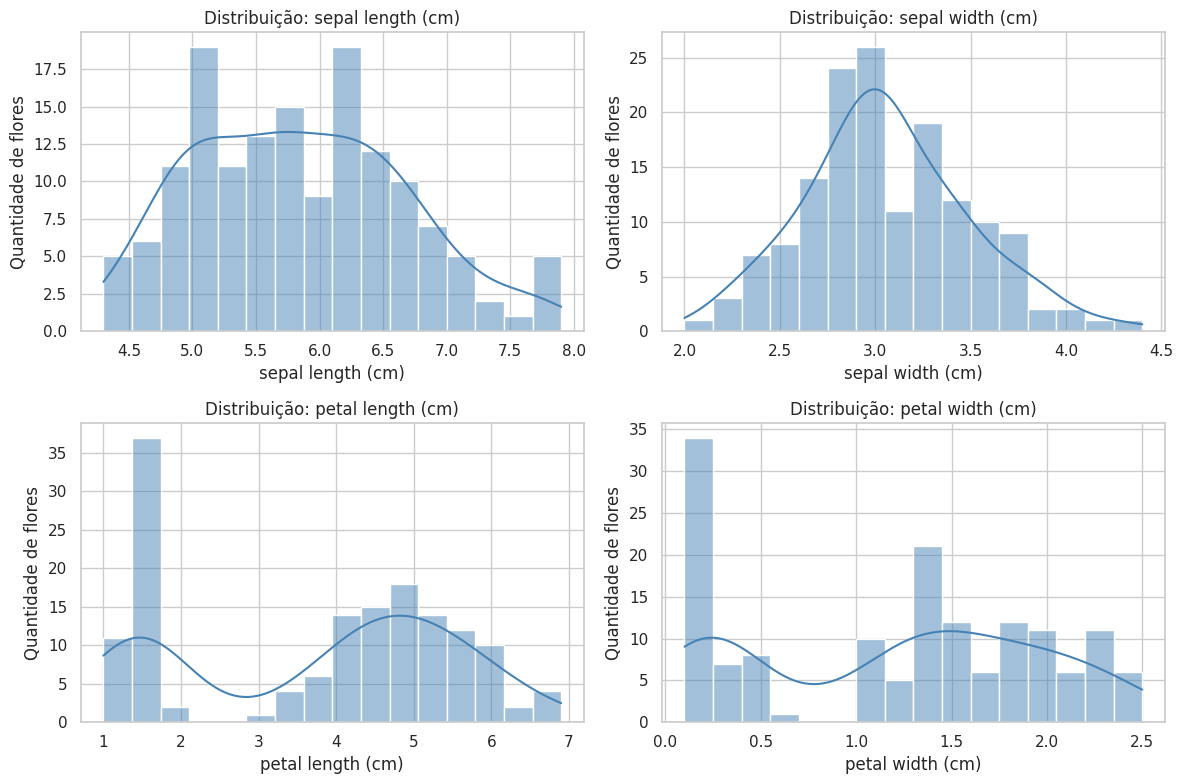

In [6]:
# um histograma para cada medida, para ver onde os valores se concentram
fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
for eixo, coluna in zip(eixos.ravel(), iris.columns):
    sns.histplot(iris[coluna], kde=True, bins=16, ax=eixo, color='steelblue')
    eixo.set_title(f'Distribuição: {coluna}')
    eixo.set_xlabel(coluna)
    eixo.set_ylabel('Quantidade de flores')
plt.tight_layout()
plt.show()

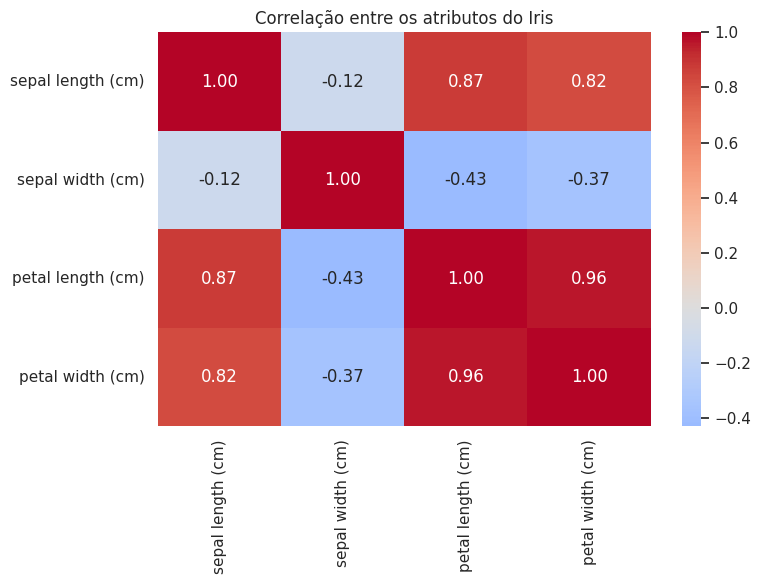

In [7]:
# correlação entre as 4 medidas (sem usar as espécies)
plt.figure(figsize=(8, 6))
sns.heatmap(iris.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlação entre os atributos do Iris')
plt.tight_layout()
plt.show()

## 4. Padronização dos dados

In [8]:
# o K-Means usa distâncias, então cada medida é padronizada (z-score): média 0 e desvio padrão 1
scaler = StandardScaler()
X_pad = scaler.fit_transform(iris) # matriz padronizada, é ela que vai para o K-Means
X_pad_df = pd.DataFrame(X_pad, columns=iris.columns)

print('Médias após padronizar (aproximadamente 0):')
print(X_pad_df.mean().round(4))
print('Desvios padrão após padronizar (aproximadamente 1):')
print(X_pad_df.std(ddof=0).round(4))

Médias após padronizar (aproximadamente 0):
sepal length (cm)   -0.0
sepal width (cm)    -0.0
petal length (cm)   -0.0
petal width (cm)    -0.0
dtype: float64
Desvios padrão após padronizar (aproximadamente 1):
sepal length (cm)    1.0
sepal width (cm)     1.0
petal length (cm)    1.0
petal width (cm)     1.0
dtype: float64


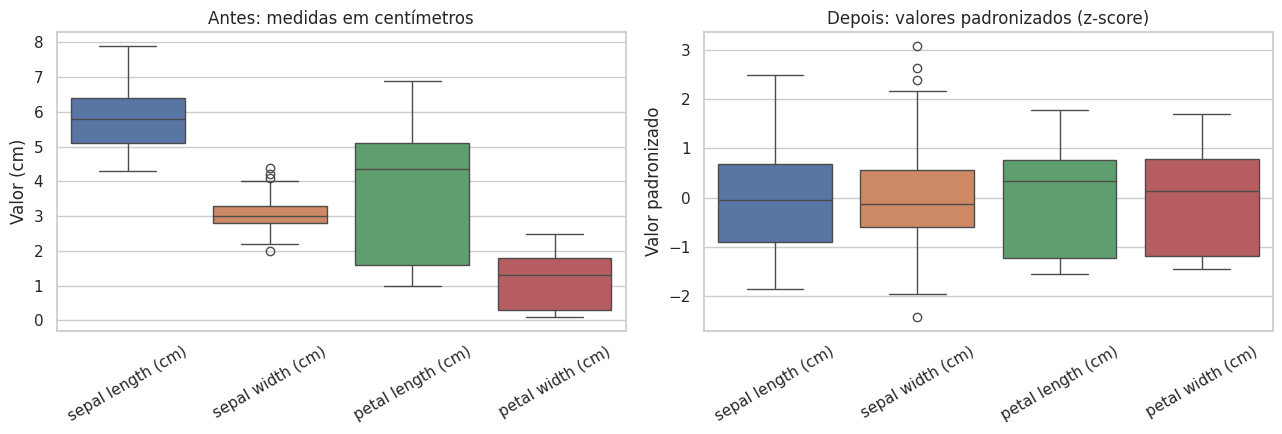

In [9]:
# comparação da dispersão antes e depois da padronização
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(data=iris, ax=eixos[0])
eixos[0].set_title('Antes: medidas em centímetros')
eixos[0].set_ylabel('Valor (cm)')

sns.boxplot(data=X_pad_df, ax=eixos[1])
eixos[1].set_title('Depois: valores padronizados (z-score)')
eixos[1].set_ylabel('Valor padronizado')

for eixo in eixos:
    eixo.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

# Parte A — Conceitos práticos

### Pergunta 1 (2,5 pontos)
**Por que não passamos a coluna das espécies (`target`) para o algoritmo K-Means durante o treinamento?**

**Resposta:** porque o K-Means é um algoritmo de aprendizado não supervisionado, ele deve descobrir os grupos olhando apenas para as medidas das flores, sem conhecer as respostas. Se as espécies fossem entregues ao algoritmo, ele deixaria de ser não supervisionado e a avaliação perderia o sentido, pois os grupos já nasceriam "contaminados" pela resposta (vazamento de informação). Além disso, target é um código (0, 1, 2) e não uma medida, então, se entrasse como atributo, ele distorceria as distâncias entre as flores.

Por isso as espécies ficam guardadas na variável especie e só são usadas depois que os grupos já foram formados e o K foi escolhido, para verificar se os clusters correspondem às espécies (ARI e matriz de contingência).

In [10]:
# evidência para a pergunta 2: quanto cada atributo pesa na variância total (e, por consequência, nas distâncias)
variancia_original = iris.var()
variancia_padronizada = X_pad_df.var()

peso = pd.DataFrame({
    'Participação sem padronizar': variancia_original / variancia_original.sum(),
    'Participação padronizada': variancia_padronizada / variancia_padronizada.sum()
})
print(peso.round(3))

                   Participação sem padronizar  Participação padronizada
sepal length (cm)                        0.150                      0.25
sepal width (cm)                         0.042                      0.25
petal length (cm)                        0.681                      0.25
petal width (cm)                         0.127                      0.25


In [11]:
# distância euclidiana entre duas flores (a primeira e a 101ª), com e sem padronização
a, b = iris.iloc[0].to_numpy(), iris.iloc[100].to_numpy()
a_pad, b_pad = X_pad[0], X_pad[100]

dif_original = (a - b) ** 2
dif_padronizada = (a_pad - b_pad) ** 2
print('Contribuição de cada atributo para a distância ao quadrado:')
print(pd.DataFrame({'Sem padronizar': dif_original / dif_original.sum(),
                    'Padronizado': dif_padronizada / dif_padronizada.sum()}, index=iris.columns).round(3))
print(f'Distância sem padronizar: {np.linalg.norm(a - b):.3f}')
print(f'Distância padronizada:    {np.linalg.norm(a_pad - b_pad):.3f}')

Contribuição de cada atributo para a distância ao quadrado:
                   Sem padronizar  Padronizado
sepal length (cm)           0.052        0.115
sepal width (cm)            0.001        0.012
petal length (cm)           0.758        0.373
petal width (cm)            0.189        0.500
Distância sem padronizar: 5.285
Distância padronizada:    4.281


### Pergunta 2 (2,5 pontos)
**O que acontece com a distância entre os pontos se não padronizarmos os dados antes de rodar o K-Means?**

**Resposta:** a distância euclidiana soma as diferenças ao quadrado de todos os atributos. Sem padronizar, os atributos que variam mais (maior amplitude e desvio padrão) acabam dominando essa soma, e os atributos que variam pouco quase não influenciam as distâncias nem a formação dos clusters. Mesmo no Iris, em que todas as medidas estão em centímetros, a tabela acima mostra que os atributos têm pesos bem diferentes na variância total (o comprimento da pétala tem muito mais peso que a largura da sépala). Com a padronização (z-score), todos os atributos passam a ter média 0 e desvio padrão 1, e cada um contribui de forma comparável para a distância.

# Parte B — Prática direta

## 3. (2,5 pontos) Complete o código abaixo para treinar o K-Means com K = 3 utilizando os dados padronizados (X_pad).


In [12]:
# 1. Instancia o modelo (K = 3, 20 inicializações, semente fixa)
modelo_simples = KMeans(n_clusters=3, n_init=20, random_state=42)

# 2. Treina o modelo e obtém o grupo de cada flor usando X_pad (as espécies não são usadas)
rotulos_simples = modelo_simples.fit_predict(X_pad)

print('Grupos atribuídos para as primeiras 10 flores:')
print(rotulos_simples[:10])

print('Quantidade de flores por cluster:')
print(pd.Series(rotulos_simples, name='Cluster').value_counts().sort_index())
print(f'Inércia (WCSS): {modelo_simples.inertia_:.3f}')

Grupos atribuídos para as primeiras 10 flores:
[1 1 1 1 1 1 1 1 1 1]
Quantidade de flores por cluster:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64
Inércia (WCSS): 139.820


## 4. (2,5 pontos) Calcule e exiba o coeficiente de Silhouette para esse modelo.

In [13]:
escore_sil = silhouette_score(X_pad, rotulos_simples)

print(f'O escore de Silhouette para K=3 é: {escore_sil:.4f}')

# interpretação da silhouette (faixas de Kaufman e Rousseeuw)
if escore_sil > 0.7:
    leitura = 'estrutura forte: grupos bem separados'
elif escore_sil > 0.5:
    leitura = 'estrutura razoável'
elif escore_sil > 0.25:
    leitura = 'estrutura fraca: há sobreposição entre grupos'
else:
    leitura = 'sem estrutura substancial'
print(f'Interpretação: {leitura}.')

O escore de Silhouette para K=3 é: 0.4599
Interpretação: estrutura fraca: há sobreposição entre grupos.


# Parte C — Experimentos do checklist

## 5. Comparação de K = 2 a K = 6


In [14]:
valores_k = range(2, 7)
inercias, silhouettes, davies = [], [], []

for k in valores_k:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMENTE) # mesmo protocolo para todos os K
    rotulos = km.fit_predict(X_pad)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_pad, rotulos))
    davies.append(davies_bouldin_score(X_pad, rotulos))

resultados_k = pd.DataFrame({'K': list(valores_k), 'Inércia': inercias,
                             'Silhouette': silhouettes, 'Davies-Bouldin': davies})
print(resultados_k.round(3))

   K  Inércia  Silhouette  Davies-Bouldin
0  2  222.362       0.582           0.593
1  3  139.820       0.460           0.834
2  4  114.092       0.384           0.877
3  5   90.808       0.346           0.945
4  6   80.022       0.322           1.058


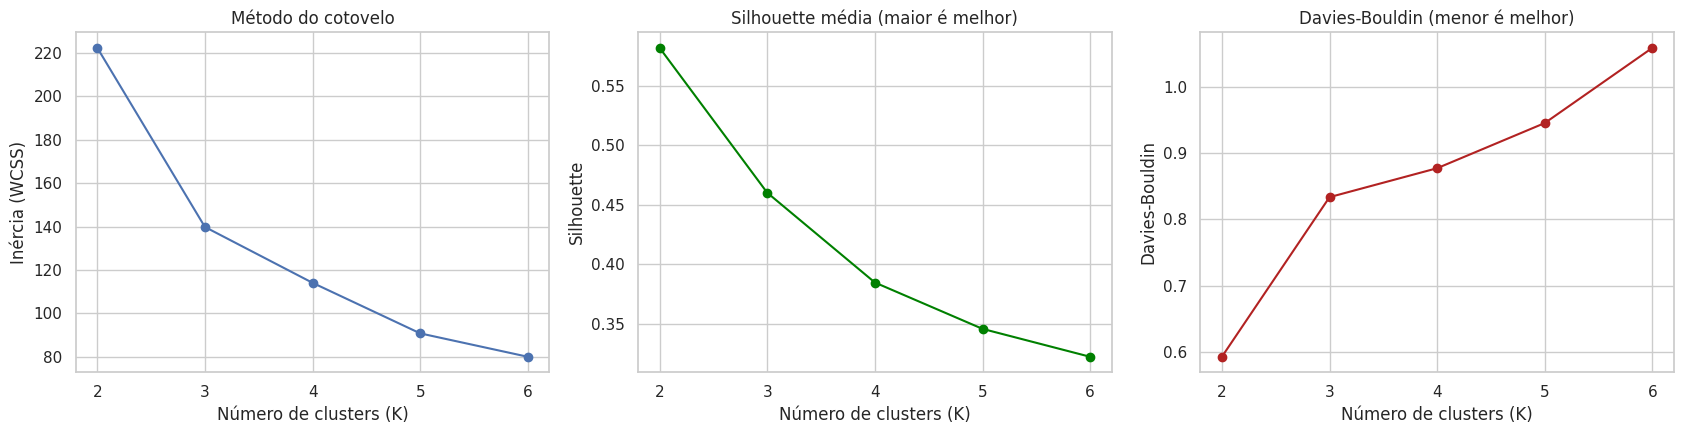

In [15]:
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.5))

eixos[0].plot(resultados_k['K'], resultados_k['Inércia'], 'o-')
eixos[0].set(title='Método do cotovelo', xlabel='Número de clusters (K)', ylabel='Inércia (WCSS)')

eixos[1].plot(resultados_k['K'], resultados_k['Silhouette'], 'o-', color='green')
eixos[1].set(title='Silhouette média (maior é melhor)', xlabel='Número de clusters (K)', ylabel='Silhouette')

eixos[2].plot(resultados_k['K'], resultados_k['Davies-Bouldin'], 'o-', color='firebrick')
eixos[2].set(title='Davies-Bouldin (menor é melhor)', xlabel='Número de clusters (K)', ylabel='Davies-Bouldin')

for eixo in eixos:
    eixo.set_xticks(list(valores_k))
plt.tight_layout()
plt.show()

## 6. Justificando a escolha de K (sem consultar as espécies)

In [16]:
# queda de inércia ao passar de K-1 para K, e o quanto essa queda diminui no passo seguinte
quedas = resultados_k['Inércia'].diff().abs()
razao = quedas / quedas.shift(-1) # queda atual / próxima queda: valor alto = a curva "dobra" naquele K
razao.index = resultados_k['K']
k_cotovelo = int(razao.dropna().idxmax())

k_silhouette = int(resultados_k.loc[resultados_k['Silhouette'].idxmax(), 'K'])
k_davies = int(resultados_k.loc[resultados_k['Davies-Bouldin'].idxmin(), 'K'])

print(f'K com maior silhouette:        {k_silhouette}')
print(f'K com menor Davies-Bouldin:    {k_davies}')
print(f'K do cotovelo (maior mudança de inclinação da inércia): {k_cotovelo}')

# regra de decisão declarada antes de olhar as espécies: vale o K de maior silhouette
# (o Davies-Bouldin serve de conferência independente)
K_escolhido = k_silhouette
print(f'Silhouette e Davies-Bouldin concordam: {k_silhouette == k_davies}')
print(f'\nK escolhido: {K_escolhido}')

print(f'\nJustificativa: a silhouette ({resultados_k.loc[resultados_k["K"] == K_escolhido, "Silhouette"].iloc[0]:.3f}) '
      f'e o índice de Davies-Bouldin ({resultados_k.loc[resultados_k["K"] == K_escolhido, "Davies-Bouldin"].iloc[0]:.3f}) '
      f'indicam que K = {K_escolhido} é a divisão geometricamente mais compacta e separada.')
if k_cotovelo != K_escolhido:
    print(f'O cotovelo da inércia aponta K = {k_cotovelo}, ou seja, os critérios não concordam totalmente. '
          f'Por isso K = {k_cotovelo} também é analisado a seguir como alternativa.')

K com maior silhouette:        2
K com menor Davies-Bouldin:    2
K do cotovelo (maior mudança de inclinação da inércia): 3
Silhouette e Davies-Bouldin concordam: True

K escolhido: 2

Justificativa: a silhouette (0.582) e o índice de Davies-Bouldin (0.593) indicam que K = 2 é a divisão geometricamente mais compacta e separada.
O cotovelo da inércia aponta K = 3, ou seja, os critérios não concordam totalmente. Por isso K = 3 também é analisado a seguir como alternativa.


**Observação:** K = 3 era o valor pedido no exercício (Parte B), mas isso é uma escolha didática. Aqui, a decisão sobre o K "ideal" vem dos critérios internos acima, e não do fato de já sabermos que o Iris tem três espécies.

## 7. Modelo final com o K escolhido

In [17]:
modelo_final = KMeans(n_clusters=K_escolhido, n_init=20, random_state=SEMENTE)
clusters = modelo_final.fit_predict(X_pad)

print('Quantidade de flores por cluster:')
print(pd.Series(clusters, name='Cluster').value_counts().sort_index())
print(f'Inércia (WCSS): {modelo_final.inertia_:.3f}')

# centroides convertidos de volta para centímetros, para interpretar cada grupo
centroides_cm = pd.DataFrame(scaler.inverse_transform(modelo_final.cluster_centers_), columns=iris.columns)
centroides_cm.index.name = 'Cluster'
print('\nCentroides em centímetros:')
print(centroides_cm.round(2))

Quantidade de flores por cluster:
Cluster
0    100
1     50
Name: count, dtype: int64
Inércia (WCSS): 222.362

Centroides em centímetros:
         sepal length (cm)  sepal width (cm)  petal length (cm)  \
Cluster                                                           
0                     6.26              2.87               4.91   
1                     5.01              3.43               1.46   

         petal width (cm)  
Cluster                    
0                    1.68  
1                    0.25  


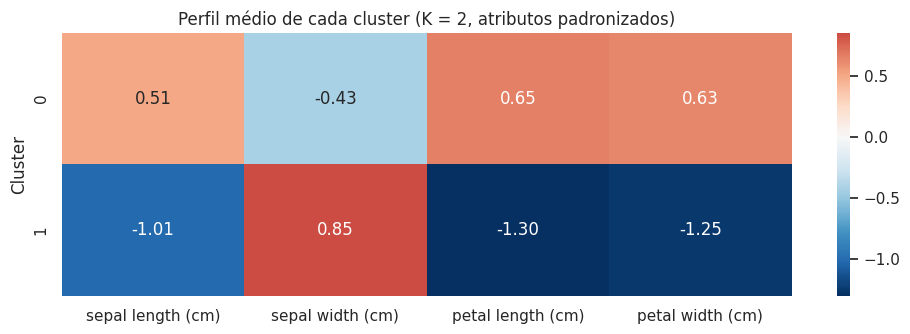

In [18]:
# perfil médio de cada cluster (atributos padronizados)
centroides_pad = pd.DataFrame(modelo_final.cluster_centers_, columns=iris.columns)
centroides_pad.index.name = 'Cluster'

plt.figure(figsize=(10, 3.5))
sns.heatmap(centroides_pad, annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title(f'Perfil médio de cada cluster (K = {K_escolhido}, atributos padronizados)')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()

Variância explicada pela CP1 e CP2: [0.73  0.229]
Variância total representada no plano: 95.8%


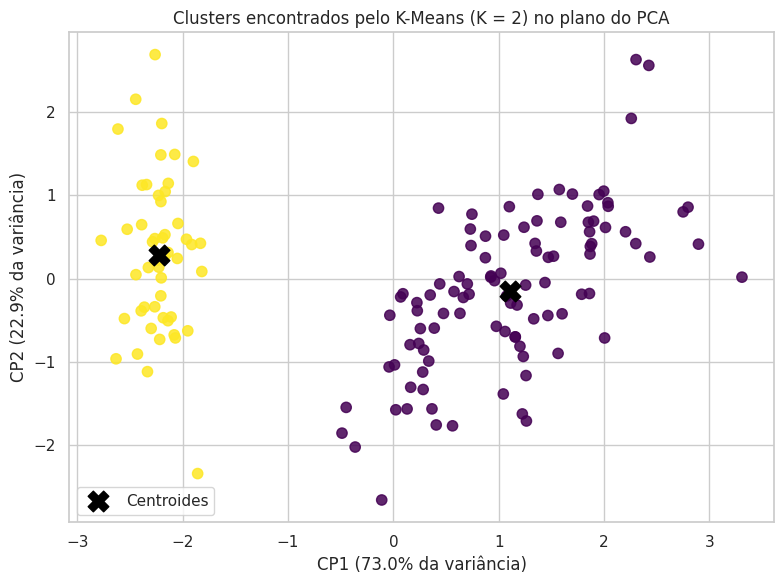

In [19]:
# PCA só para visualizar: projeta as 4 medidas em 2 eixos de maior variância (não é clustering)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_pad)
print('Variância explicada pela CP1 e CP2:', np.round(pca.explained_variance_ratio_, 3))
print(f'Variância total representada no plano: {pca.explained_variance_ratio_.sum():.1%}')

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', s=55, alpha=0.85)
plt.scatter(pca.transform(modelo_final.cluster_centers_)[:, 0], pca.transform(modelo_final.cluster_centers_)[:, 1],
            c='black', marker='X', s=220, label='Centroides')
plt.xlabel(f'CP1 ({pca.explained_variance_ratio_[0]:.1%} da variância)')
plt.ylabel(f'CP2 ({pca.explained_variance_ratio_[1]:.1%} da variância)')
plt.title(f'Clusters encontrados pelo K-Means (K = {K_escolhido}) no plano do PCA')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Comparação com as espécies reais (somente agora)

O K já foi escolhido sem olhar as espécies, então agora é permitido compará-los. O **ARI** (Adjusted Rand Index) mede a concordância entre os grupos e as espécies: 1 é concordância perfeita, perto de 0 é o esperado ao acaso. A matriz de contingência **não é** uma matriz de confusão, pois o número do cluster é arbitrário e não corresponde ao código da espécie.

In [20]:
# compara o K escolhido e K = 3 (o valor pedido no exercício)
ks_comparar = sorted({K_escolhido, 3})
rotulos_por_k = {k: KMeans(n_clusters=k, n_init=20, random_state=SEMENTE).fit_predict(X_pad) for k in ks_comparar}

linhas = []
for k, rot in rotulos_por_k.items():
    linhas.append({'K': k, 'Silhouette': silhouette_score(X_pad, rot),
                   'Davies-Bouldin': davies_bouldin_score(X_pad, rot),
                   'ARI (comparação externa)': adjusted_rand_score(especies, rot)})
metricas = pd.DataFrame(linhas)
print(metricas.round(4).to_string(index=False))

 K  Silhouette  Davies-Bouldin  ARI (comparação externa)
 2      0.5818          0.5933                    0.5681
 3      0.4599          0.8336                    0.6201


K = 2
Cluster      0   1
setosa       0  50
versicolor  50   0
virginica   50   0 

K = 3
Cluster      0   1   2
setosa       0  50   0
versicolor  39   0  11
virginica   14   0  36 



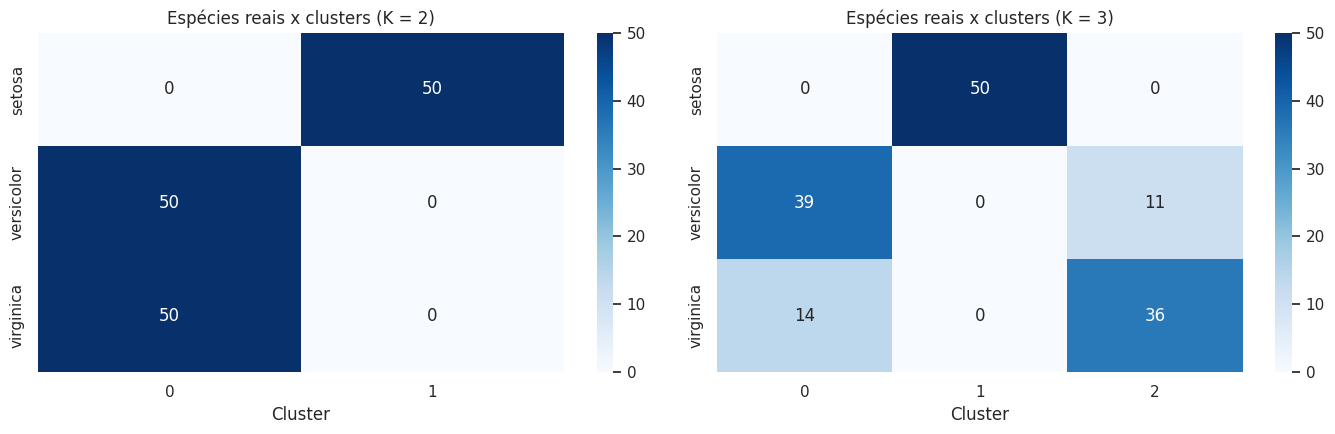

In [21]:
# matriz de contingência: quantas flores de cada espécie caíram em cada cluster
fig, eixos = plt.subplots(1, len(ks_comparar), figsize=(7 * len(ks_comparar), 4.5))
eixos = np.atleast_1d(eixos)

for eixo, (k, rot) in zip(eixos, rotulos_por_k.items()):
    tabela = pd.crosstab(pd.Series(especies.to_numpy(), name='Espécie'), pd.Series(rot, name='Cluster'))
    tabela.index = [nomes_especies[i] for i in tabela.index]
    print(f'K = {k}')
    print(tabela, '\n')
    sns.heatmap(tabela, annot=True, fmt='d', cmap='Blues', ax=eixo)
    eixo.set_title(f'Espécies reais x clusters (K = {k})')
plt.tight_layout()
plt.show()

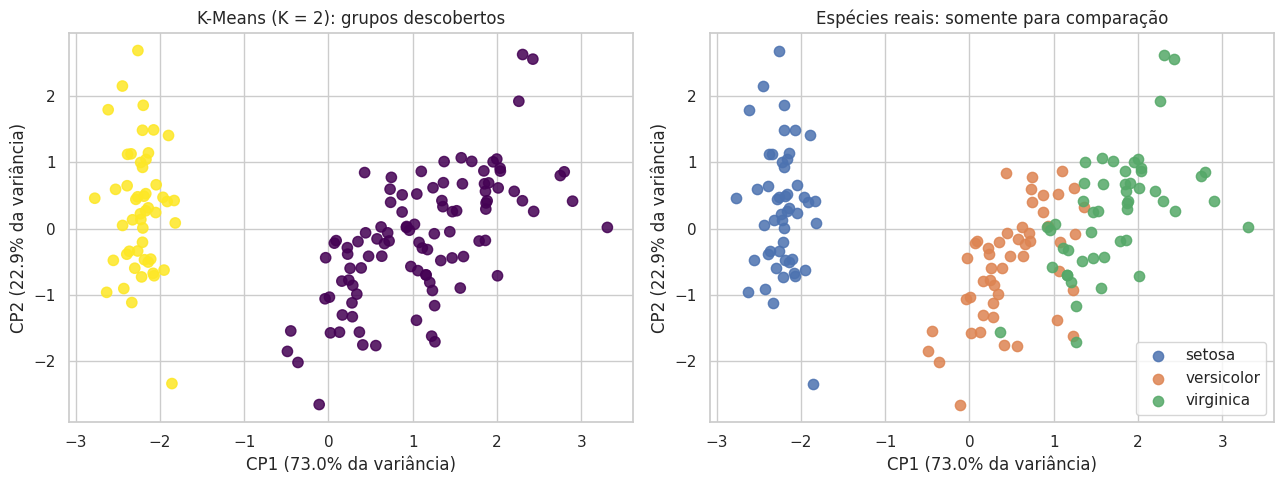

In [22]:
# os grupos descobertos ao lado das espécies reais, no mesmo plano do PCA
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

eixos[0].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', s=55, alpha=0.85)
eixos[0].set_title(f'K-Means (K = {K_escolhido}): grupos descobertos')

for i, nome in enumerate(nomes_especies):
    eixos[1].scatter(X_pca[especies == i, 0], X_pca[especies == i, 1], s=55, alpha=0.85, label=nome)
eixos[1].set_title('Espécies reais: somente para comparação')
eixos[1].legend()

for eixo in eixos:
    eixo.set_xlabel(f'CP1 ({pca.explained_variance_ratio_[0]:.1%} da variância)')
    eixo.set_ylabel(f'CP2 ({pca.explained_variance_ratio_[1]:.1%} da variância)')
plt.tight_layout()
plt.show()

## 9. Com e sem padronização

Treinamos o K-Means nas medidas em centímetros e nas medidas padronizadas, com o mesmo K, para ver o efeito da padronização.

In [23]:
linhas = []
for k in ks_comparar:
    rot_bruto = KMeans(n_clusters=k, n_init=20, random_state=SEMENTE).fit_predict(iris)
    rot_pad = rotulos_por_k[k]
    linhas.append({'K': k, 'Representação': 'Sem padronização',
                   'Silhouette': silhouette_score(iris, rot_bruto),
                   'ARI vs espécies': adjusted_rand_score(especies, rot_bruto)})
    linhas.append({'K': k, 'Representação': 'Com padronização',
                   'Silhouette': silhouette_score(X_pad, rot_pad),
                   'ARI vs espécies': adjusted_rand_score(especies, rot_pad)})

comparacao = pd.DataFrame(linhas)
print(comparacao.round(3).to_string(index=False))
print('\nAtenção: as silhouettes são calculadas em espaços diferentes e não são diretamente equivalentes.')

 K    Representação  Silhouette  ARI vs espécies
 2 Sem padronização       0.681            0.540
 2 Com padronização       0.582            0.568
 3 Sem padronização       0.553            0.730
 3 Com padronização       0.460            0.620

Atenção: as silhouettes são calculadas em espaços diferentes e não são diretamente equivalentes.


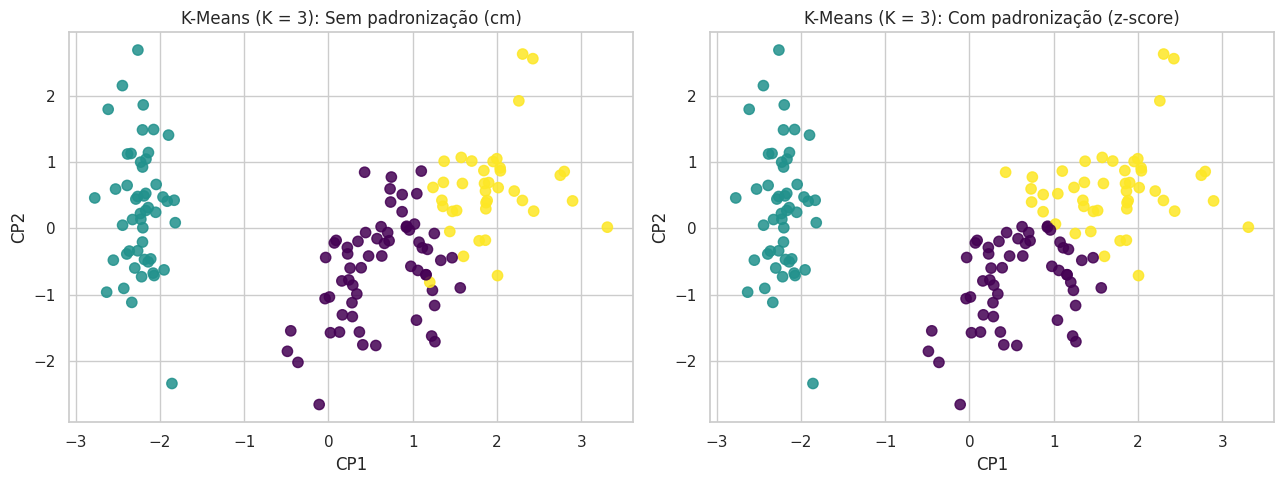

In [24]:
# a comparação visual: os mesmos K-Means (K = 3) no plano do PCA, sem e com padronização
rot_bruto3 = KMeans(n_clusters=3, n_init=20, random_state=SEMENTE).fit_predict(iris)
rot_pad3 = rotulos_por_k[3]

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for eixo, rot, titulo in zip(eixos, [rot_bruto3, rot_pad3], ['Sem padronização (cm)', 'Com padronização (z-score)']):
    eixo.scatter(X_pca[:, 0], X_pca[:, 1], c=rot, cmap='viridis', s=55, alpha=0.85)
    eixo.set_title(f'K-Means (K = 3): {titulo}')
    eixo.set_xlabel('CP1')
    eixo.set_ylabel('CP2')
plt.tight_layout()
plt.show()

## 10. Conclusão crítica

In [25]:
# CONCLUSÃO: o texto é montado com os números calculados acima
sil = resultados_k.set_index('K')['Silhouette']
ari_K = metricas.set_index('K')['ARI (comparação externa)']
sil_K = metricas.set_index('K')['Silhouette']

print(f'Escolha de K. Usando apenas critérios internos, a maior silhouette ({sil[k_silhouette]:.3f}) ocorreu em K = {k_silhouette} '
      f'e o menor Davies-Bouldin em K = {k_davies}; o cotovelo da inércia apontou K = {k_cotovelo}. '
      f'Por isso o K adotado foi {K_escolhido}. Com K = 3 (valor do exercício) a silhouette foi {sil[3]:.3f}.')

print(f'\nComparação com as espécies. Só depois de escolher K, o ARI de K = {K_escolhido} foi {ari_K[K_escolhido]:.3f}'
      + (f' e o de K = 3 foi {ari_K[3]:.3f}.' if K_escolhido != 3 else '.'))

# quantas espécies ficaram misturadas em K = 3
tab3 = pd.crosstab(especies.to_numpy(), rotulos_por_k[3])
puras = int((tab3.max(axis=1) == 50).sum())
misturadas = int(tab3.shape[0] - puras)
print(f'Em K = 3, {puras} espécie(s) caíram inteiras em um único cluster e {misturadas} ficaram divididas entre clusters, '
      f'com {int(tab3.to_numpy().sum() - tab3.max(axis=0).sum())} flores em cluster dominado por outra espécie.')

tabK = pd.crosstab(especies.to_numpy(), rotulos_por_k[K_escolhido])
if K_escolhido == 2 and tabK.loc[0].max() == 50 and tabK.loc[1].idxmax() == tabK.loc[2].idxmax():
    print(f'Com K = 2, a {nomes_especies[0]} fica isolada em um cluster e a {nomes_especies[1]} e a {nomes_especies[2]} são reunidas '
          'no outro. O K-Means separou o que é muito diferente, mas não distinguiu as duas espécies parecidas.')

linha_bruto = comparacao[(comparacao['K'] == 3) & (comparacao['Representação'] == 'Sem padronização')].iloc[0]
linha_pad = comparacao[(comparacao['K'] == 3) & (comparacao['Representação'] == 'Com padronização')].iloc[0]
print(f'\nEfeito da padronização (K = 3). ARI sem padronizar: {linha_bruto["ARI vs espécies"]:.3f}; com padronização: {linha_pad["ARI vs espécies"]:.3f}.')
if linha_bruto['ARI vs espécies'] > linha_pad['ARI vs espécies']:
    print('Neste conjunto a padronização não aumentou a concordância com as espécies. Isso não a torna dispensável: ela evita que um '
          'atributo domine a distância só por causa da escala. No Iris, os atributos que dominam a distância sem padronizar '
          '(as medidas da pétala) são justamente os que melhor distinguem as espécies, o que favorece o resultado sem padronização.')
else:
    print('A padronização aumentou ou manteve a concordância com as espécies, coerente com o objetivo de equilibrar a contribuição de cada atributo.')

Escolha de K. Usando apenas critérios internos, a maior silhouette (0.582) ocorreu em K = 2 e o menor Davies-Bouldin em K = 2; o cotovelo da inércia apontou K = 3. Por isso o K adotado foi 2. Com K = 3 (valor do exercício) a silhouette foi 0.460.

Comparação com as espécies. Só depois de escolher K, o ARI de K = 2 foi 0.568 e o de K = 3 foi 0.620.
Em K = 3, 1 espécie(s) caíram inteiras em um único cluster e 2 ficaram divididas entre clusters, com 25 flores em cluster dominado por outra espécie.
Com K = 2, a setosa fica isolada em um cluster e a versicolor e a virginica são reunidas no outro. O K-Means separou o que é muito diferente, mas não distinguiu as duas espécies parecidas.

Efeito da padronização (K = 3). ARI sem padronizar: 0.730; com padronização: 0.620.
Neste conjunto a padronização não aumentou a concordância com as espécies. Isso não a torna dispensável: ela evita que um atributo domine a distância só por causa da escala. No Iris, os atributos que dominam a distância sem pa

### Limitações e cuidados

- **Encontrar K clusters não significa encontrar as K espécies.** O K-Means agrupa por proximidade geométrica nas medidas, e não por taxonomia. Quando o melhor K pelos critérios internos é diferente de 3, isso não é um erro do algoritmo: os objetivos são diferentes.
- **Sobreposição entre duas espécies.** As espécies *versicolor* e *virginica* têm medidas parecidas e se sobrepõem, então nenhum agrupamento por distância separa as duas perfeitamente; já a *setosa* é bem distinta das demais.
- **Silhouette e Davies–Bouldin favorecem grupos compactos e bem separados**, e por isso tendem a apontar poucos clusters quando duas espécies se misturam. Elas não garantem que os grupos tenham significado biológico, e um ARI alto também não prova isso.
- **O método do cotovelo é subjetivo:** a curva da inércia pode não ter uma dobra nítida, e K = 2 não pode ser candidato ao cotovelo porque K = 1 não foi testado.
- **O K-Means supõe grupos compactos e aproximadamente esféricos**, é sensível à escala dos atributos, a valores extremos e à inicialização (por isso foram usadas 20 inicializações e semente fixa).
- **Dados limitados:** são só 150 flores e 4 medidas. As conclusões valem para este conjunto e para a escolha de atributos feita.
- A projeção em 2 dimensões (PCA) é apenas uma ferramenta de visualização e pode esconder sobreposições que existem nas 4 dimensões.

## Checklist de entrega

- [x] Respondi às duas perguntas teóricas da Parte A com minhas palavras.
- [x] Completei e executei os exercícios 3 e 4 da Parte B (K-Means com K = 3 e Silhouette).
- [x] Executei a comparação de K = 2 a K = 6.
- [x] Apresentei gráficos com títulos e eixos identificados.
- [x] Justifiquei K sem consultar as espécies reais.
- [x] Calculei e interpretei o ARI apenas após escolher K.
- [x] Comparei os resultados com e sem padronização.
- [x] Escrevi uma conclusão crítica com limitações.